# Publication-ready fern imputation figures

Matplotlib / Seaborn equivalents of **Lambda signal code.R**, **Quantile plot.R**, and **Morans I plotting code.R**.

Figures: transposed Pagel’s λ heatmap (comparisons on y, trait × minimum/maximum on x); three quantile bar-plot groups; ≥80%-consistent LIPA overview; and paired minimum/maximum LIPA scatterplots for each retained comparison × trait.

All figures export as PDF, SVG, and 300-dpi PNG. No synthetic experimental data are used.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from IPython.display import display


## 1. Configuration

In [2]:
DATA_DIR = Path(".").absolute()              # Folder holding the summary CSVs
OUT_DIR = DATA_DIR.parent / "figures"

LAMBDA_CSV = DATA_DIR / "Pagels_Lambda_Delta_Mean_SD_Across_Seeds.csv"
QUANTILE_CSV = DATA_DIR / "Trait_Quantile_Delta_Mean_SD_Across_Seeds.csv"
LIPA_CSV = DATA_DIR / "LIPA_80pct_Plotting_Data.csv"

import sys
sys.path.insert(0, str(next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis_utils.py").is_file())))
import analysis_utils as au

# Canonical names and orderings shared by all notebooks (analysis_utils.py).
TRAIT_ORDER = [au.TRAIT_LABELS[t] for t in au.TRAIT_ORDER]
COMPARISON_ORDER = [au.contrast_label(a, b) for a, b in [
    ("baseline", "environment"), ("baseline", "phylogeny"), ("environment", "phylogeny"),
    ("environment", "full"), ("phylogeny", "full")]]
BOUND_ORDER = [au.BOUND_LABELS[b] for b in au.BOUND_ORDER]
N_QUANTILES = 6

# Publication defaults: editable labels, embedded TrueType fonts where supported.
sns.set_theme(context="paper", style="ticks", font="DejaVu Sans", font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 12, "legend.fontsize": 9,
})
COLORS = {au.BOUND_LABELS["min"]: "#2b5c8f", au.BOUND_LABELS["max"]: "#d95f02"}

def save_figure(fig, stem, layout="tight"):
    if layout != "tight":
        fig.set_constrained_layout(True)
        fig.savefig(OUT_DIR / f"{stem}.pdf")
    else:
        fig.savefig(OUT_DIR / f"{stem}.pdf", bbox_inches=layout)
    print(f"Saved figure to {OUT_DIR.absolute() / f'{stem}.pdf'}")

def check_columns(df, required, name):
    missing = sorted(set(required) - set(df.columns))
    if missing:
        raise ValueError(f"{name}: missing required CSV columns: {missing}")

def standardize_labels(df):
    df = df.copy()
    # R heatmap uses wrapped labels; normalize so the two files match.
    for column in ("Trait_Display", "Comparison", "Bound"):
        if column in df:
            df[column] = df[column].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    df["Comparison"] = df["Comparison"].str.replace("->", "→", regex=False)
    df["Comparison"] = df["Comparison"].str.replace(r"\s*→\s*", " → ", regex=True)
    return df

def warn_unknown(df):
    for col, allowed in [("Trait_Display", TRAIT_ORDER),
                         ("Comparison", COMPARISON_ORDER), ("Bound", BOUND_ORDER)]:
        unknown = sorted(set(df[col].dropna()) - set(allowed))
        if unknown:
            print(f"WARNING: unrecognized {col} values (not plotted): {unknown}")


## 2. Read and validate source summaries

In [3]:
def read_lambda(path=LAMBDA_CSV):
    df = standardize_labels(pd.read_csv(path))
    check_columns(df, ["Trait_Display", "Comparison", "Bound", "Mean_Lambda"], "Lambda")
    if "SD_Lambda" not in df:
        df["SD_Lambda"] = np.nan
    for col in ("Mean_Lambda", "SD_Lambda"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    warn_unknown(df)
    keys = ["Trait_Display", "Bound", "Comparison"]
    if df.duplicated(keys).any():
        raise ValueError("Lambda CSV has duplicate Trait_Display / Bound / Comparison rows")
    out_of_range = df["Mean_Lambda"].dropna().loc[lambda x: ~x.between(0, 1)]
    if len(out_of_range):
        print("WARNING: Pagel’s lambda values outside the R color scale [0, 1] will be clipped.")
    return df

def read_quantile(path=QUANTILE_CSV):
    df = standardize_labels(pd.read_csv(path))
    check_columns(df, ["Comparison", "Trait_Display", "Bound", "Quantile",
                       "Mean_Prop_Delta", "SD_Prop_Delta"], "Quantile")
    for col in ("Quantile", "Mean_Prop_Delta", "SD_Prop_Delta"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    if df["Quantile"].dropna().mod(1).ne(0).any():
        raise ValueError("Quantile must contain integer quantile numbers")
    warn_unknown(df)
    keys = ["Comparison", "Trait_Display", "Bound", "Quantile"]
    if df.duplicated(keys).any():
        raise ValueError("Quantile CSV has duplicate Comparison / Trait / Bound / Quantile rows")
    return df

# Supply the real CSV files in DATA_DIR before executing plotting cells.
# Example: lambda_data = read_lambda(); quantile_data = read_quantile()


## 3. Pagel’s λ heatmap — transposed, grouped x-axis labels

**Rows:** model comparisons. **Columns:** traits grouped into **Minimum** and **Maximum** predictions (or just the available bound). The outer trait labels are bold; bound labels are the individual x ticks, and vertical separators distinguish trait groups. As in the R source, cell values are mean Pagel’s λ ± SD across seeds, with a fixed 0–1 `YlGnBu` scale.

In [4]:
def plot_lambda_heatmap(data, *, show_sd=True, missing_cells=True,
                        bound_order=BOUND_ORDER, cmap="YlGnBu",
                        stem="Lambda signal", save=False):
    observed = data.loc[data["Trait_Display"].isin(TRAIT_ORDER)
                        & data["Comparison"].isin(COMPARISON_ORDER)
                        & data["Bound"].isin(bound_order)].copy()
    if observed.empty:
        raise ValueError("No recognized trait/comparison/bound rows found")
    pairs = [(trait, bound) for trait in TRAIT_ORDER for bound in bound_order
             if ((observed["Trait_Display"] == trait) & (observed["Bound"] == bound)).any()]
    columns = pd.MultiIndex.from_tuples(pairs, names=["Trait_Display", "Bound"])
    means = observed.pivot(index="Comparison", columns=["Trait_Display", "Bound"],
                           values="Mean_Lambda").reindex(index=COMPARISON_ORDER, columns=columns)
    sds = observed.pivot(index="Comparison", columns=["Trait_Display", "Bound"],
                         values="SD_Lambda").reindex(index=COMPARISON_ORDER, columns=columns)
    values = means.to_numpy(dtype=float)
    width = max(9.5, 1.05 * len(pairs) + 2.8)
    fig, ax = plt.subplots(figsize=(width, 5.0))
    fig.subplots_adjust(left=0.17, right=0.89, bottom=0.36, top=0.94)
    palette = plt.get_cmap(cmap).copy()
    palette.set_bad("#e6e6e6")
    im = ax.imshow(np.ma.masked_invalid(values), cmap=palette,
                   norm=Normalize(0, 1), aspect="auto", interpolation="nearest")
    ax.set_yticks(np.arange(len(COMPARISON_ORDER)))
    ax.set_yticklabels(COMPARISON_ORDER)
    ax.set_xticks(np.arange(len(pairs)))
    ax.set_xticklabels(["Min" if bound == "Minimum value" else "Max"
                        for _, bound in pairs], fontsize=9)
    ax.tick_params(which="major", length=0, pad=6)
    traits = columns.get_level_values("Trait_Display").tolist()
    # Group headings appear BELOW the Min/Max tick labels.
    # x-axis transform uses data coordinates horizontally and axes fractions vertically.
    # The separators continue below the heatmap THROUGH the Min/Max label band,
    # finishing before the separate trait-name row.
    group_transform = ax.get_xaxis_transform()
    start = 0
    for end in range(1, len(traits) + 1):
        if end == len(traits) or traits[end] != traits[start]:
            ax.text((start + end - 1) / 2, -0.125,
                    traits[start].replace(" length", "\nlength"),
                    transform=group_transform, ha="center", va="top", weight="bold",
                    fontsize=9.5, clip_on=False)
            if end < len(traits):
                # More visible than the cell grid, and deliberately taller than
                # the image area to separate the Min/Max labels as well.
                ax.plot([end - 0.5, end - 0.5], [-0.165, 1],
                        color="white", lw=2.5, transform=group_transform,
                        clip_on=False, zorder=5)
            start = end
    ax.set_xticks(np.arange(-0.5, len(pairs), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(COMPARISON_ORDER), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.1)
    ax.tick_params(which="minor", bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            val = values[i, j]
            if not np.isfinite(val):
                if missing_cells:
                    ax.text(j, i, "NA", ha="center", va="center", color="#777777", fontsize=10)
                continue
            sd = sds.iat[i, j]
            label = f"{val:.2f}" + (f"\n± {sd:.2f}" if show_sd and np.isfinite(sd) else "")
            rgba = im.cmap(im.norm(val))
            luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
            ax.text(j, i, label, ha="center", va="center", fontsize=10,
                    color="white" if luminance < 0.47 else "#151515")
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.022)
    cb.set_label("Mean Pagel’s λ")
    cb.outline.set_visible(False)
    if save:
        save_figure(fig, stem)
    return fig, ax, means


Saved figure to /home/smonaco/newzeland-plants/figures/Lambda signal.pdf


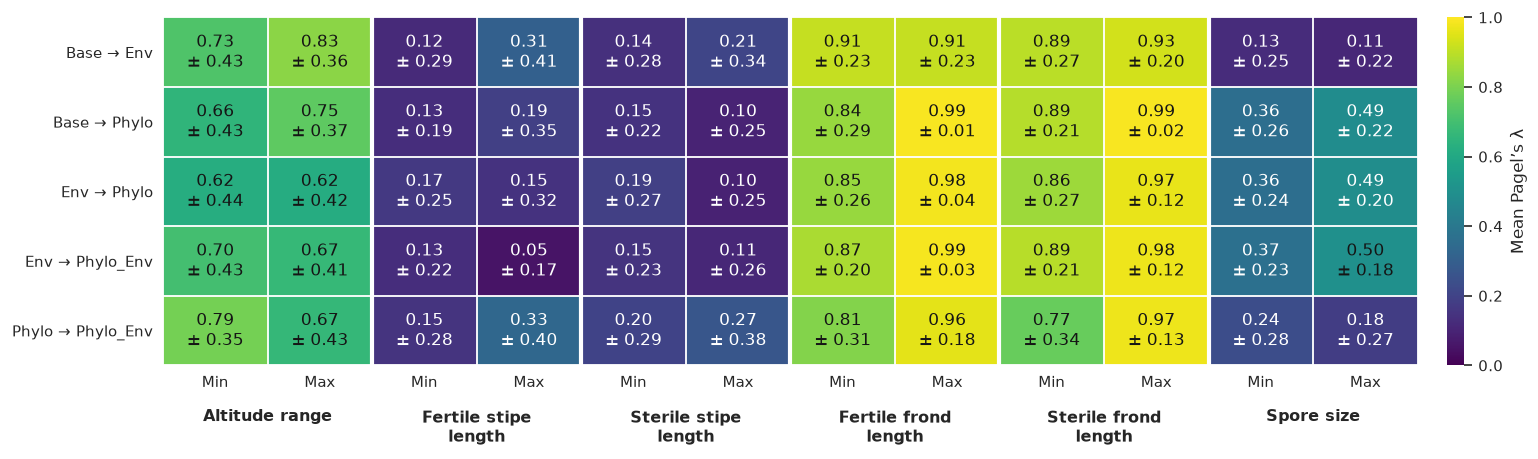

In [5]:
lambda_data = read_lambda()
fig_lambda, ax_lambda, heatmap_table = plot_lambda_heatmap(lambda_data, save=True, cmap="viridis")
plt.show()

## 4. Quantile delta figures — faceted mean ± SD bars

Recreates all **three** sets of comparisons from the R script. Each facet has independent y-limits, retains the dashed zero reference, and plots minimum and maximum prediction error side by side. Quantile 1 is the smallest observed trait values; quantile 6 is the largest.

## 5. Generate Pagel’s λ and quantile figures

Place the two summary CSV files in `DATA_DIR`. The following cell runs those four figures when both files exist; otherwise it reports which input is missing without blocking the independent LIPA plotting section.

In [6]:
def plot_quantile_group(df, comparisons, title, stem, save=True, showbars=False,
                        legend_bbox_to_anchor=(0.5, 0.)):
    sub = df[df["Comparison"].isin(comparisons)
             & df["Trait_Display"].isin(TRAIT_ORDER)
             & df["Bound"].isin(BOUND_ORDER)].copy()
    if sub.empty:
        raise ValueError(f"No records available for {title}")
    active_comps = [c for c in comparisons if c in sub["Comparison"].unique()]
    traits = [t for t in TRAIT_ORDER if t in sub["Trait_Display"].unique()]
    nr, nc = len(active_comps), len(traits)
    fig, axes = plt.subplots(nr, nc, figsize=(max(11.5, 2.55 * nc), 2.35 * nr + 1.15),
                             squeeze=False, sharex=True, sharey=False)
    x = np.arange(1, N_QUANTILES + 1, dtype=float)
    width = 0.36
    for r, comp in enumerate(active_comps):
        for c, trait in enumerate(traits):
            ax = axes[r, c]
            cell = sub[(sub["Comparison"] == comp) & (sub["Trait_Display"] == trait)]
            for bi, bound in enumerate(BOUND_ORDER):
                points = cell[cell["Bound"] == bound].set_index("Quantile").reindex(range(1, N_QUANTILES+1))
                mu = points["Mean_Prop_Delta"].to_numpy(dtype=float)
                sd = points["SD_Prop_Delta"].to_numpy(dtype=float)
                pos = x + (bi - 0.5) * width
                good = np.isfinite(mu)
                ax.bar(pos[good], mu[good], width=width, color=COLORS[bound],
                       edgecolor="#383838", linewidth=0.45,
                       label=bound if (r == 0 and c == 0) else None, zorder=2)
                good_sd = good & np.isfinite(sd) & (sd >= 0)
                if good_sd.any() and showbars:
                    ax.errorbar(pos[good_sd], mu[good_sd], yerr=sd[good_sd],
                                fmt="none", ecolor="#242424", elinewidth=0.8,
                                capsize=2, capthick=0.8, zorder=4)
            ax.axhline(0, ls="--", color="#b22222", lw=0.9, alpha=0.85, zorder=1)
            ax.set_xticks(range(1, N_QUANTILES + 1))
            ax.set_xlim(0.45, N_QUANTILES + 0.55)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.grid(axis="y", linewidth=0.45, alpha=0.23, zorder=0)
            ax.spines[["top", "right"]].set_visible(False)
            if r == 0:
                ax.set_title(trait.replace(" length", "\nlength"), fontsize=10, weight="bold", pad=11)
            if c == 0:
                ax.set_ylabel(comp + "\nMean normalised Δ error", fontsize=9.2, weight="bold")
            if r == nr - 1:
                ax.set_xlabel("Observed quantile", fontsize=9)
    # Custom legend so it also works when the first facet has only one bound.
    from matplotlib.patches import Patch
    handles = [Patch(facecolor=COLORS[b], edgecolor="#383838", label=b) for b in BOUND_ORDER]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=legend_bbox_to_anchor,
               ncol=2, frameon=False)
    # fig.suptitle(title, x=0.5, y=1.01, fontsize=14, weight="bold")
    
    # fig.subplots_adjust(left=0.09, right=0.99, bottom=0.11, top=0.83, wspace=0.34, hspace=0.42)
    plt.tight_layout()
    if save:
        save_figure(fig, stem)
    return fig, axes


Saved figure to /home/smonaco/newzeland-plants/figures/trait_quantiles_base_transitions.pdf
Saved figure to /home/smonaco/newzeland-plants/figures/trait_quantiles_phyloenv_transitions.pdf
Saved figure to /home/smonaco/newzeland-plants/figures/trait_quantiles_env_vs_phylo.pdf


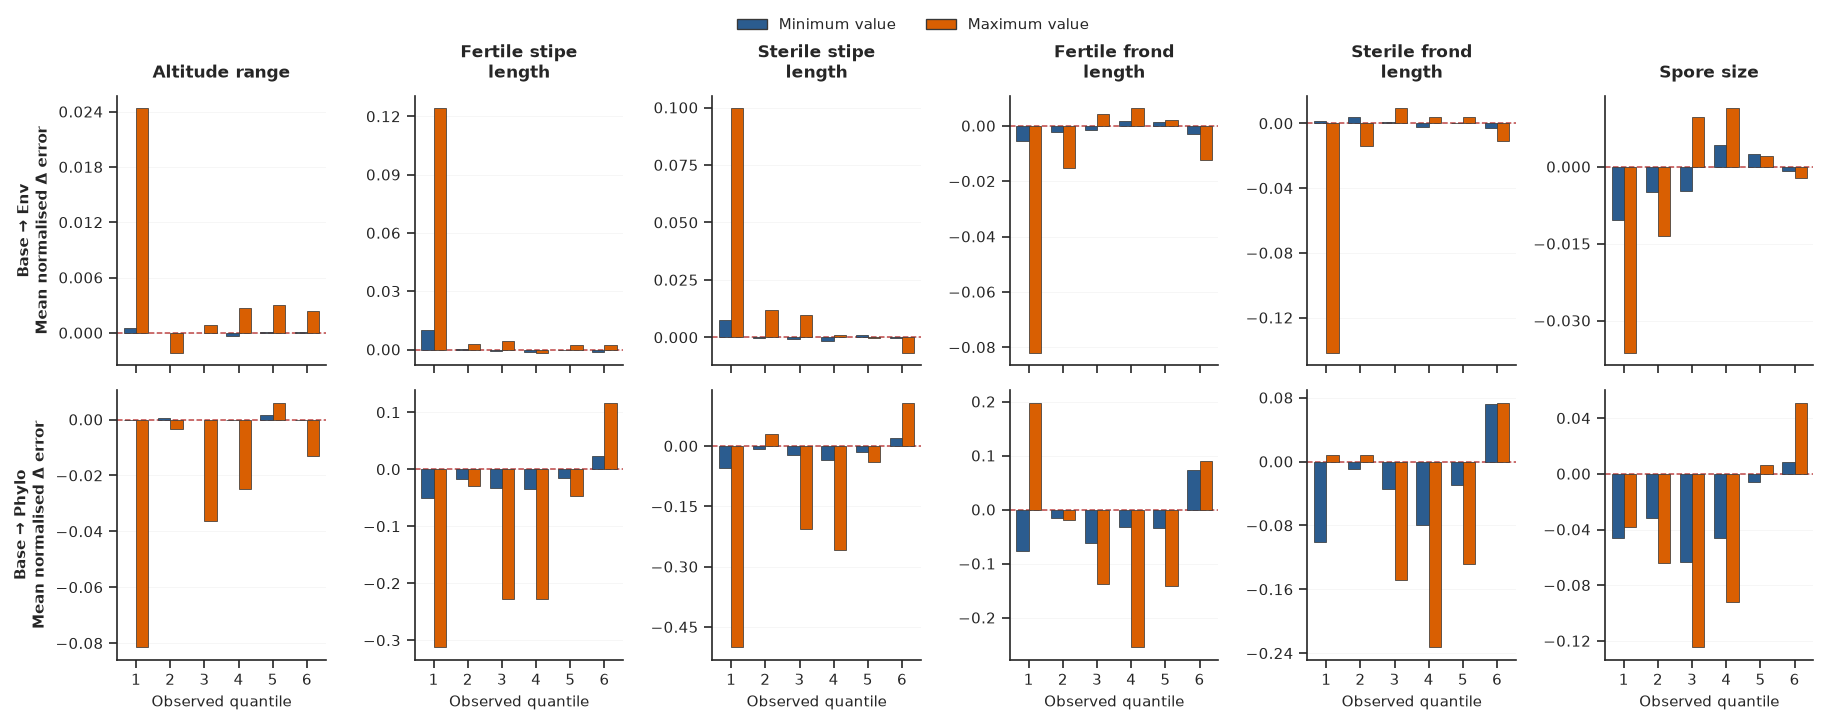

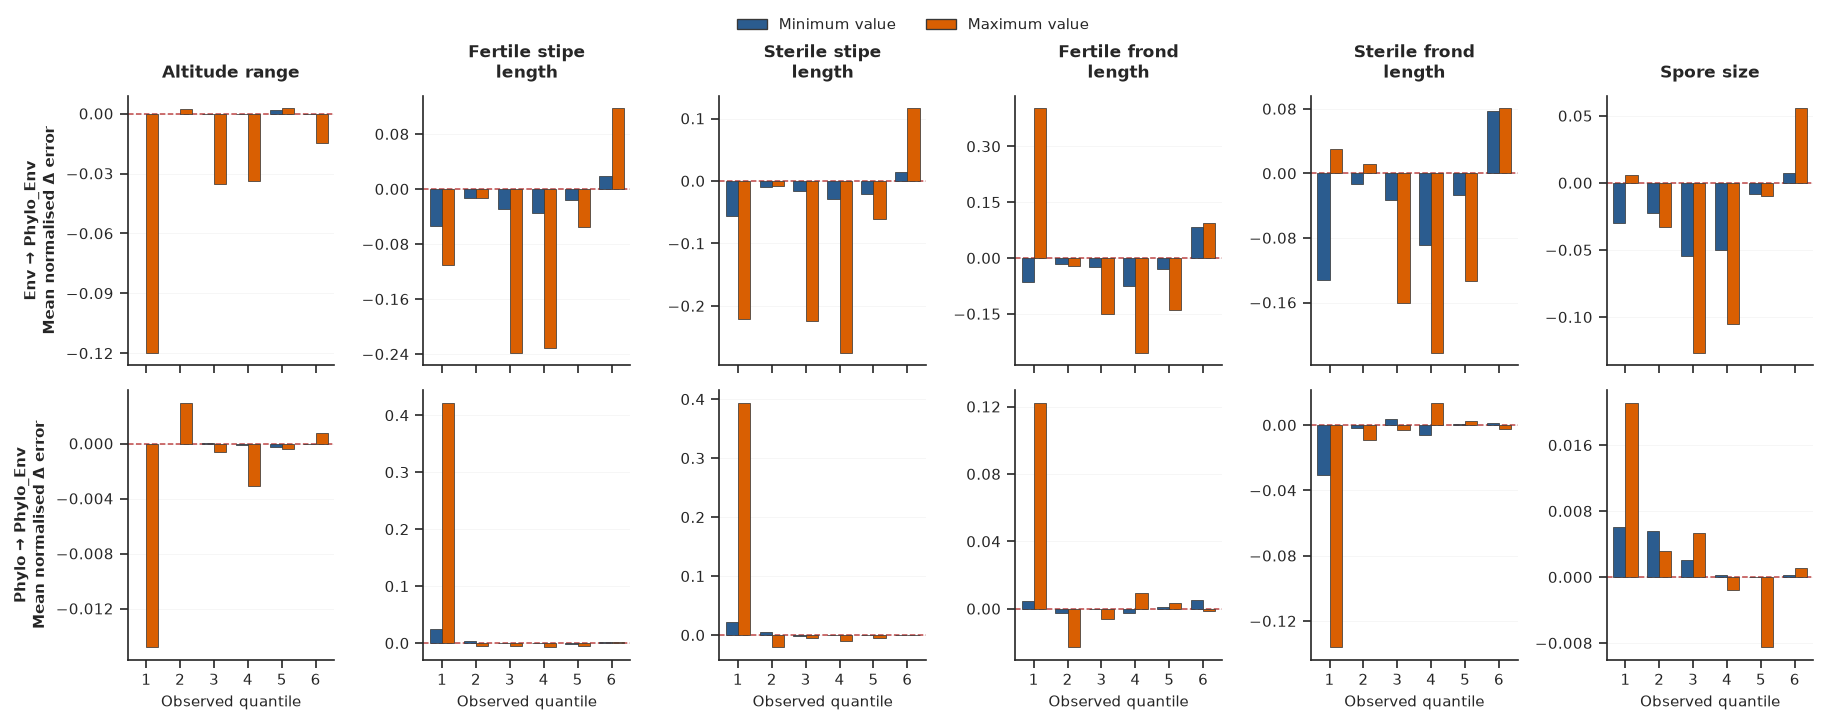

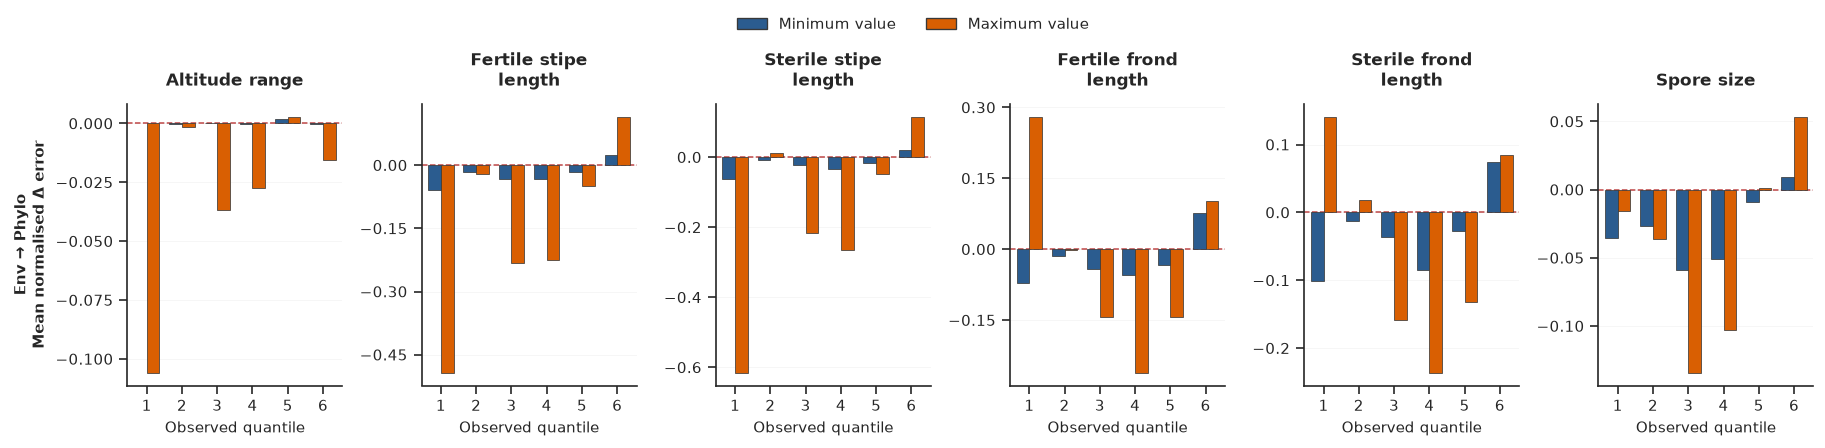

In [7]:
quantile_data = read_quantile()

comparisons, title, filename = ["Base → Env", "Base → Phylo"], "Baseline model transitions across trait quantiles", "trait_quantiles_base_transitions"
legend_bbox_to_anchor = (0.5, 1.03)
fig, axes = plot_quantile_group(quantile_data, comparisons, title, filename, legend_bbox_to_anchor=legend_bbox_to_anchor, save=True)

comparisons, title, filename =  ["Env → Phylo_Env", "Phylo → Phylo_Env"], "Effect of combined phylogenetic + environmental model", "trait_quantiles_phyloenv_transitions"
fig, axes = plot_quantile_group(quantile_data, comparisons, title, filename, legend_bbox_to_anchor=legend_bbox_to_anchor, save=True)

comparisons, title, filename =  ["Env → Phylo"], "Environmental versus phylogenetic imputation", "trait_quantiles_env_vs_phylo"
legend_bbox_to_anchor = (0.5, 1.07)
fig, axes = plot_quantile_group(quantile_data, comparisons, title, filename, legend_bbox_to_anchor=legend_bbox_to_anchor, save=True)


## Notes for manuscript preparation

- **Pagel’s λ:** comparison rows, grouped trait / min–max columns; fixed sequential color scale 0–1. NA is shown explicitly. SD is across seeds, not a confidence interval.
- **Quantiles:** error bars are ±1 SD across seeds. The signed delta is *source error minus destination error*.
- **LIPA:** requires the exported summary `LIPA_80pct_Plotting_Data.csv` from the supplied Moran’s I R script. This plotting-ready CSV includes classification and species-level seed summaries; the notebook does **not** recompute LIPA significance from spatial data.
- **Vector graphics:** PDF/SVG support editing in illustration programs; PNG is 300 dpi.

## 6. Local Moran’s I (LIPA): ≥80% consistent species

This section reproduces **both** figure types in `Morans I plotting code.R` from its one exported dataset `LIPA_80pct_Plotting_Data.csv`. Retain only comparisons × traits with at least one species consistently in the *same significant category* in ≥80% of imputation seeds. Nonconsistent points appear grey in paired scatterplots; the overview shows consistent points only. `Median_p_value` is a descriptive across-seed summary, **not a pooled significance test**.

In [8]:
from matplotlib.lines import Line2D
from matplotlib import patheffects
import re

LIPA_THRESHOLD = 0.80
P_CUTOFF = 0.05
LIPA_CLASSES = ["High-High (Hotspot)", "Low-Low (Coldspot)",
                "High-Low (Outlier)", "Low-High (Outlier)",
                "Non-significant / inconsistent"]
LIPA_COLORS = dict(zip(LIPA_CLASSES, ["#7570B3", "#E67E22", "#E84393", "#1B9E77", "#BFBFBF"]))
LIPA_LEGEND = dict(zip(LIPA_CLASSES, ["Hotspots", "Cold spots", "Outliers (High-Low)",
                                      "Outliers (Low-High)", "Non-significant"]))
TRAIT_ALIASES = au.TRAIT_LABELS

def read_lipa(path=LIPA_CSV):
    d = pd.read_csv(path)
    required = ["Comparison", "Trait", "Trait_Display", "Bound", "Species",
                "Mean_Prop_Delta", "Median_p_value", "Plot_Category", "Is_Consistent_80"]
    check_columns(d, required, "LIPA")
    d = standardize_labels(d)
    d["Bound"] = d["Bound"].str.replace(r"\s+value$", "", regex=True)
    for col in ("Mean_Prop_Delta", "Median_p_value", "Consistency_Percent", "Consistency_Proportion"):
        if col in d:
            d[col] = pd.to_numeric(d[col], errors="coerce")
    d["Is_Consistent_80"] = d["Is_Consistent_80"].astype(str).str.lower().isin(["true", "t", "1", "yes"])
    d["Species_Display"] = d["Species"].astype(str).str.replace("_", " ", regex=False)
    d["Plot_Category"] = d["Plot_Category"].fillna("Non-significant / inconsistent")
    d.loc[~d["Is_Consistent_80"], "Plot_Category"] = "Non-significant / inconsistent"
    if "Consistency_Proportion" in d:
        d.loc[d["Is_Consistent_80"] & (d["Consistency_Proportion"] < LIPA_THRESHOLD), "Is_Consistent_80"] = False
    d.loc[~d["Is_Consistent_80"], "Plot_Category"] = "Non-significant / inconsistent"
    valid = d.loc[d["Is_Consistent_80"], ["Comparison", "Trait"]].drop_duplicates()
    if valid.empty:
        raise ValueError("No Comparison × Trait has ≥80%-consistent significant species")
    d = d.merge(valid, on=["Comparison", "Trait"], how="inner", validate="many_to_one")
    d["minus_log10_p"] = -np.log10(d["Median_p_value"].clip(lower=np.finfo(float).tiny).fillna(1))
    return d

def lipa_legend_handles(include_grey=True):
    classes = LIPA_CLASSES if include_grey else LIPA_CLASSES[:-1]
    return [Line2D([], [], linestyle="", marker="o", markersize=8,
                   markerfacecolor=LIPA_COLORS[k], markeredgecolor="white",
                   label=LIPA_LEGEND[k]) for k in classes]

def safe_filename(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")


### 6a. Main consistency overview

One dot per consistent species × trait × comparison × bound, colored by LIPA class, labeled by consistency percentage. Panels are comparison × bound (two columns). Species are ordered by their occurrence frequency across the retained data. Individual panels show only species occurring in that panel.

### 6c. Render all Moran’s I figures

The original R script exports only `LIPA_80pct_Plotting_Data.csv`. Place that CSV in `DATA_DIR` to reproduce the figures below. Output count depends on which comparison × trait combinations pass the 80% criterion.

In [11]:
from matplotlib.colors import to_rgb


def plot_lipa_overview(data, stem="lipa_80pct_consistency_overview",
                    species_order=None, annotate=True,
                    width_in=8.0, row_height=0.21, fs=7, save=True):
    """
    LIPA consistency overview.
      rows    = bound (Maximum / Minimum)
      columns = model comparison
      x       = trait, y = species (grouped by genus, same order everywhere)
      colour  = LIPA category, marker area = % of imputation seeds agreeing
    Requires matplotlib >= 3.7 (outside legend placement).
    """
    S_MIN, S_MAX = 130, 190          # marker area (pt^2) for 80 % ... 100 %

    d = data.loc[data["Is_Consistent_80"]].copy()
    if d.empty:
        raise ValueError("No ≥80%-consistent species to plot")
    for col in ("Comparison", "Bound"):
        d[col] = d[col].astype(str)

    # --- consistency in % -> marker size ------------------------------------
    pct = pd.Series(np.nan, index=d.index)
    if "Consistency_Percent" in d:
        pct = pd.to_numeric(d["Consistency_Percent"], errors="coerce")
    if "Consistency_Proportion" in d:
        pct = pct.fillna(pd.to_numeric(d["Consistency_Proportion"], errors="coerce") * 100)
    d["_pct"] = pct
    d["_size"] = S_MIN + (pct.fillna(80).clip(80, 100) - 80) / 20 * (S_MAX - S_MIN)

    # --- ordering -----------------------------------------------------------
    bounds = [b for b in ("Maximum", "Minimum") if b in set(d["Bound"])]
    bounds += [b for b in d["Bound"].unique() if b not in bounds]
    comps = [c for c in COMPARISON_ORDER if c in set(d["Comparison"])]
    comps += [c for c in d["Comparison"].unique() if c not in comps]
    traits = [t for t in TRAIT_ORDER if t in set(d["Trait_Display"])]
    traits += [t for t in d["Trait_Display"].dropna().unique() if t not in traits]
    xmap = {t: i for i, t in enumerate(traits)}
    xlabels = [t.replace(" length", "\nlength") for t in traits]

    # one global species order (genera together, most frequent genus first),
    # so a species sits at the same relative position in every panel
    cnt = d.groupby("Species_Display").size()
    genus = pd.Series({s: str(s).split()[0] for s in cnt.index})
    gtot = cnt.groupby(genus).sum()
    auto = sorted(cnt.index, key=lambda s: (-gtot[genus[s]], genus[s], -cnt[s], str(s)))
    if species_order is None:
        species_order = auto
    else:
        species_order = [s for s in species_order if s in cnt.index] + \
                        [s for s in auto if s not in species_order]

    rows_sp = {b: [s for s in species_order
                   if s in set(d.loc[d["Bound"] == b, "Species_Display"])]
               for b in bounds}

    def text_color(c):
        r, g, b = to_rgb(c)
        return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else "black"

    # --- figure -------------------------------------------------------------
    nrows, ncols = len(bounds), len(comps)
    n_per_row = [len(rows_sp[b]) for b in bounds]
    figsize = (width_in, row_height * sum(n_per_row) + 0.6 * nrows + 0.7)

    # rc = {"font.size": 9, "axes.linewidth": 0.8, "axes.edgecolor": "#444444",
    #       "pdf.fonttype": 42, "ps.fonttype": 42}          # editable text in PDF/EPS

    rc = {"font.size": fs, "axes.linewidth": 0.6,
          "axes.linewidth": 0.8, "axes.edgecolor": "#444444",
          "xtick.major.width": 0.6, "xtick.major.size": 2.5,
          "grid.linewidth": 0.4,
          "font.family": "serif",            # match your document font
          "pdf.fonttype": 42, "ps.fonttype": 42}

    with plt.rc_context(rc):
        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False,
                                 sharey="row", layout="constrained",
                                 gridspec_kw={"height_ratios": [n + 1 for n in n_per_row]})

        for i, b in enumerate(bounds):
            sp = rows_sp[b]
            n = len(sp)
            ypos = {s: n - 1 - k for k, s in enumerate(sp)}
            gen = [str(s).split()[0] for s in sp]

            for j, c in enumerate(comps):
                ax = axes[i, j]

                # alternating genus bands
                k, blk = 0, 0
                while k < n:
                    e = k
                    while e + 1 < n and gen[e + 1] == gen[k]:
                        e += 1
                    if blk % 2 == 0:
                        ax.axhspan(n - 1 - e - 0.5, n - 1 - k + 0.5,
                                   color="#f3f3f6", lw=0, zorder=0)
                    blk, k = blk + 1, e + 1

                # points
                sub = d[(d["Bound"] == b) & (d["Comparison"] == c)]
                if sub.empty:
                    ax.text(0.5, 0.5, "no species ≥80 % consistent", transform=ax.transAxes,
                            ha="center", va="center", fontsize=fs, color="#888888",
                            fontstyle="italic")
                for cat, g in sub.groupby("Plot_Category"):
                    x = g["Trait_Display"].map(xmap).to_numpy(float)
                    y = g["Species_Display"].map(ypos).to_numpy(float)
                    col = LIPA_COLORS.get(cat, "#BFBFBF")
                    ax.scatter(x, y, s=g["_size"].to_numpy(), c=[col], edgecolors="white",
                               linewidths=0.5, zorder=3)
                    if annotate:
                        tc = text_color(col)
                        for xi, yi, p in zip(x, y, g["_pct"]):
                            if pd.notna(p):
                                ax.text(xi, yi, f"{int(round(p))}", ha="center", va="center",
                                        fontsize=fs - 1.5, fontweight="bold", color=tc, zorder=4)

                # axes cosmetics
                ax.set_xlim(-0.6, len(traits) - 0.4)
                ax.set_ylim(-0.6, n - 0.4)
                ax.set_xticks(range(len(traits)))
                ax.set_xticklabels(xlabels, fontsize=fs)
                ax.grid(axis="x", color="#e3e3e3", linewidth=0.6)
                ax.set_axisbelow(True)
                ax.spines[["top", "right", "left"]].set_visible(False)
                ax.tick_params(axis="y", length=0)
                ax.tick_params(axis="x", length=3, color="#888888")

                if j == 0:                                   # y axis is shared along the row
                    ax.set_yticks(range(n))
                    ax.set_yticklabels(sp[::-1], fontsize=fs, fontstyle="italic")
                    ax.set_ylabel(f"{b} bound", fontweight="bold", fontsize=fs+1, labelpad=8)
                else:
                    ax.tick_params(labelleft=False)
                if i == 0:
                    ax.set_title(c, fontweight="bold", fontsize=fs+1, pad=8)

        # --- legend: only categories actually shown + size key --------------
        pref = ["Hotspots", "Cold spots", "Outliers (High-Low)", "Outliers (Low-High)"]
        present = set(d["Plot_Category"].dropna())
        cats = [c for c in pref if c in present] + sorted(present - set(pref))
        handles = [Line2D([], [], marker="o", ls="", markersize=8,
                          markerfacecolor=LIPA_COLORS.get(c, "#BFBFBF"),
                          markeredgecolor="white", label=c) for c in cats]
        handles.append(Line2D([], [], ls="", label="   Seed consistency:"))
        for v in (80, 90, 100):
            s = S_MIN + (v - 80) / 20 * (S_MAX - S_MIN)
            handles.append(Line2D([], [], marker="o", ls="", markersize=np.sqrt(s),
                                  markerfacecolor="#9a9a9a", markeredgecolor="white",
                                  label=f"{v}%"))
        fig.legend(handles=handles, loc="outside upper center", ncol=len(handles),
                   frameon=False, fontsize=fs, handletextpad=0.2, columnspacing=.9)
        # fig.supxlabel("Only species in the same significant LIPA category in ≥80% "
                    #   "of imputation seeds are shown.", fontsize=8.5, color="#555555")

        if save:
            save_figure(fig, stem, layout="constrained")
    return fig, axes

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_consistency_overview.pdf


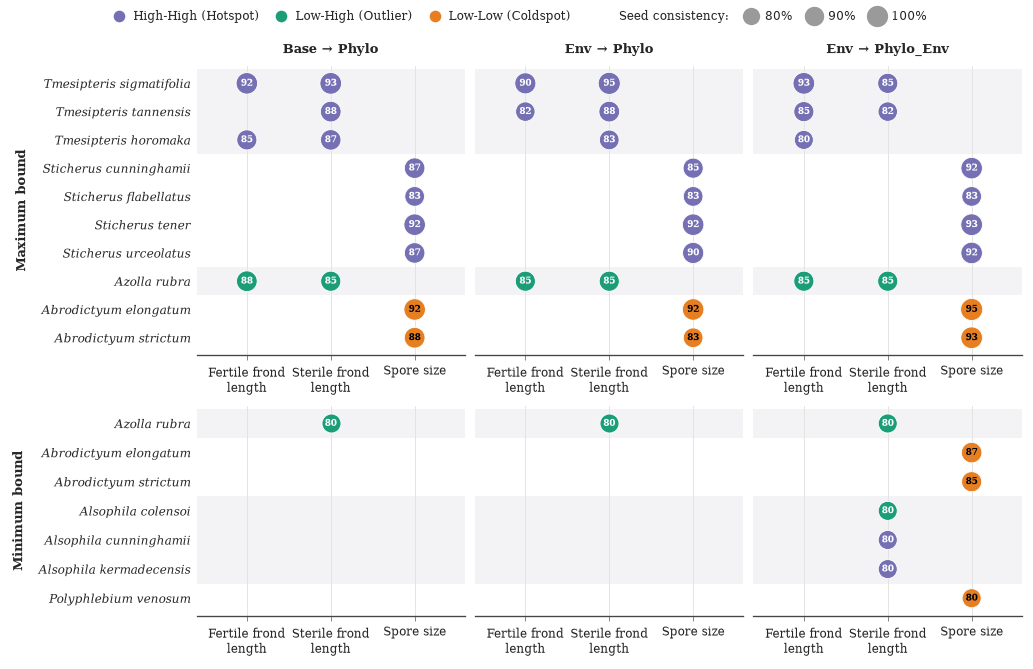

In [12]:
lipa_data = read_lipa()
# print(f"LIPA plotting records: {len(lipa_data):,}")
# display(lipa_data.head(4))
fig_lipa_main, axes_lipa_main = plot_lipa_overview(lipa_data, width_in=8.5)
plt.show()


### 6b. Trait-specific paired Minimum / Maximum LIPA scatterplots

For every comparison × trait with ≥80%-consistent species, plot **all** its species (grey if inconsistent). Colored, larger points are the reproducible hotspot/coldspot/outlier species, with italic species labels. The x axis is mean proportional delta across seeds; y axis is −log₁₀(median seed-level p-value); dashed horizontal reference is p = 0.05. Panels use independent x/y axis limits, as in the R source.

In [13]:
import matplotlib.patheffects as pe

def _place_labels(ax, xy, texts, obs_xy, obs_w, obs_r, fs):
    """
    Greedy collision-aware label placement (no extra dependency).
    For every label, candidate positions are tried on rings of increasing
    radius around its point. Each candidate is scored on:
    - staying inside the axes
    - not overlapping labels already placed
    - not covering other markers (coloured ones weigh more than grey)
    - being close to its point
    A thin leader line is drawn only when the label ends up far from its point.
    Call after fig.canvas.draw(), so the transforms are final.
    """
    fig = ax.figure
    rend = fig.canvas.get_renderer()
    k = fig.dpi / 72.0                                   # points -> pixels
    ab = ax.get_window_extent(rend)
    xmin, xmax, ymin, ymax = ab.x0 + 2, ab.x1 - 2, ab.y0 + 2, ab.y1 - 2

    P = ax.transData.transform(np.asarray(xy, float))
    O = ax.transData.transform(np.asarray(obs_xy, float))
    obs_w, obs_r = np.asarray(obs_w, float), np.asarray(obs_r, float) * k

    # text sizes in pixels
    sizes = []
    for s in texts:
        t = ax.text(0, 0, s, fontsize=fs, fontstyle="italic")
        bb = t.get_window_extent(rend)
        sizes.append((bb.width + 2 * k, bb.height + 2 * k))
        t.remove()

    dirs = [(1, 1), (1, -1), (-1, 1), (-1, -1), (1, 0), (-1, 0), (0, 1), (0, -1)]
    cands = [(r * dx / np.hypot(dx, dy), r * dy / np.hypot(dx, dy), r)
             for r in (5, 9, 14, 20, 28, 38) for dx, dy in dirs]

    placed = []
    for i in np.argsort(-P[:, 1]):                       # top to bottom
        w, h = sizes[i]
        px, py = P[i]
        best = None
        for dx, dy, r in cands:
            ox, oy = dx * k, dy * k
            x0 = px + ox if dx > .01 else (px + ox - w if dx < -.01 else px - w / 2)
            y0 = py + oy if dy > .01 else (py + oy - h if dy < -.01 else py - h / 2)
            x1, y1 = x0 + w, y0 + h

            score = 0.4 * r
            if x0 < xmin or x1 > xmax or y0 < ymin or y1 > ymax:
                score += 1e6
            for a0, b0, a1, b1 in placed:
                ix, iy = min(x1, a1) - max(x0, a0), min(y1, b1) - max(y0, b0)
                if ix > 0 and iy > 0:
                    score += 1e4 + ix * iy
            ddx = np.maximum(np.maximum(x0 - O[:, 0], O[:, 0] - x1), 0)
            ddy = np.maximum(np.maximum(y0 - O[:, 1], O[:, 1] - y1), 0)
            score += (obs_w * (np.hypot(ddx, ddy) < obs_r)).sum()

            if best is None or score < best[0]:
                best = (score, dx, dy, r, (x0, y0, x1, y1))

        _, dx, dy, r, box = best
        placed.append(box)
        ann = ax.annotate(
            texts[i], xy[i], xytext=(dx, dy), textcoords="offset points",
            ha="left" if dx > .01 else "right" if dx < -.01 else "center",
            va="bottom" if dy > .01 else "top" if dy < -.01 else "center",
            fontsize=fs, fontstyle="italic", color="#1a1a1a", zorder=5,
            annotation_clip=False,
            arrowprops=(dict(arrowstyle="-", color="#777777", lw=0.5,
                             shrinkA=0, shrinkB=2.5) if r > 10 else None))
        ann.set_in_layout(False)
        ann.set_path_effects([pe.withStroke(linewidth=1.8, foreground="white")])


def plot_lipa_trait_pair(data, comparison, trait, *, p_cutoff=P_CUTOFF, stem=None,
                         width_in=7.0, height_in=3.6, fs=7, show_title=True):
    """
    Delta-improvement vs -log10(p) for one Comparison x Trait, one panel per bound.
    Sized for a full-width LaTeX figure (7.0 in, text in real points).
    Requires matplotlib >= 3.7 (outside legend placement).
    """
    sub = data.loc[(data["Comparison"] == comparison) & (data["Trait"] == trait)].copy()
    if sub.empty or not sub["Is_Consistent_80"].any():
        raise ValueError("Comparison × Trait does not contain ≥80%-consistent species")
    sub = sub[np.isfinite(sub["Mean_Prop_Delta"]) & np.isfinite(sub["minus_log10_p"])]

    bounds = [b for b in ("Minimum", "Maximum") if (sub["Bound"] == b).any()]
    grey = LIPA_CLASSES[-1]                              # "Non-significant"
    ycut = -np.log10(p_cutoff)
    ytop = max(sub["minus_log10_p"].max(), ycut)

    rc = {"font.size": fs, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
          "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
          "font.family": "serif", "pdf.fonttype": 42, "ps.fonttype": 42}

    with plt.rc_context(rc):
        fig, axes = plt.subplots(1, len(bounds), figsize=(width_in, height_in),
                                 squeeze=False, sharey=True, layout="constrained")
        jobs = []

        for ax, bound in zip(axes.flat, bounds):
            one = sub.loc[sub["Bound"] == bound]

            # grey background first: small, translucent, rasterised (dense clouds)
            for cls in LIPA_CLASSES:
                pts = one.loc[one["Plot_Category"] == cls]
                if pts.empty:
                    continue
                is_bg = cls == grey
                ax.scatter(pts["Mean_Prop_Delta"], pts["minus_log10_p"],
                           s=14 if is_bg else 48, c=LIPA_COLORS[cls],
                           alpha=0.55 if is_bg else 1.0,
                           edgecolors="white", linewidths=0.3 if is_bg else 0.6,
                           zorder=2 if is_bg else 3, rasterized=is_bg)

            ax.axhline(ycut, ls="--", color="#E57373", lw=0.9, zorder=1)
            ax.axvline(0, ls=":", color="#b5b5b5", lw=0.6, zorder=1)

            # limits with head-room so labels have somewhere to go
            x = one["Mean_Prop_Delta"]
            pad = 0.12 * ((x.max() - x.min()) or 1.0)
            ax.set_xlim(x.min() - pad, x.max() + pad)
            ax.set_ylim(-0.03 * ytop, 1.12 * ytop)

            ax.set_title(f"{bound} bound", fontsize=fs + 1, fontweight="bold",
                         loc="left", pad=5)
            ax.set_xlabel("Proportional Delta Improvement", fontweight="bold")
            if ax is axes.flat[0]:
                ax.set_ylabel("−log₁₀(median seed-level p-value)", fontweight="bold")
            ax.grid(color="#e6e6e6", linewidth=0.4)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)

            lab = one.loc[one["Is_Consistent_80"]]
            if lab.empty:
                ax.text(0.5, 0.93, "no species ≥80 % consistent", transform=ax.transAxes,
                        ha="center", va="top", fontsize=fs - 0.5,
                        fontstyle="italic", color="#888888")
            else:
                is_col = (one["Plot_Category"] != grey).to_numpy()
                jobs.append((ax,
                             lab[["Mean_Prop_Delta", "minus_log10_p"]].to_numpy(float),
                             lab["Species_Display"].astype(str).tolist(),
                             one[["Mean_Prop_Delta", "minus_log10_p"]].to_numpy(float),
                             np.where(is_col, 30.0, 3.0),     # penalty for covering a marker
                             np.where(is_col, 3.6, 2.2)))     # marker radius (pt)

        # legend: only categories that are present + cutoff line
        present = [c for c in LIPA_CLASSES if (sub["Plot_Category"] == c).any()]
        handles = [Line2D([], [], marker="o", ls="", markersize=4.5 if c == grey else 6.5,
                          markerfacecolor=LIPA_COLORS[c], markeredgecolor="white",
                          markeredgewidth=0.4, label=c) for c in present]
        handles.append(Line2D([], [], ls="--", color="#E57373", lw=0.9,
                              label=f"p = {p_cutoff:g}"))
        fig.legend(handles=handles, loc="outside lower center", ncol=len(handles),
                   frameon=False, fontsize=fs, handletextpad=0.3, columnspacing=1.2)

        if show_title:
            name = TRAIT_ALIASES.get(str(trait),
                                     str(sub["Trait_Display"].iloc[0]).replace("\n", " "))
            fig.suptitle(f"{name}   |   {comparison}", fontsize=fs + 2, fontweight="bold")

        # layout is final after one draw -> now place labels
        fig.canvas.draw()
        for job in jobs:
            _place_labels(*job, fs=fs)

        save_figure(fig, stem or f"lipa_80pct_{safe_filename(comparison)}__{safe_filename(trait)}")
    return fig, axes

def plot_all_lipa_pairs(data):
    scenarios = data.loc[data["Is_Consistent_80"], ["Comparison", "Trait"]].drop_duplicates()
    comp_rank = {v: i for i, v in enumerate(COMPARISON_ORDER)}
    scenarios = scenarios.assign(_order=scenarios["Comparison"].map(comp_rank).fillna(999))
    figures = {}
    for _, row in scenarios.sort_values(["_order", "Trait"]).iterrows():
        comp, trait = row["Comparison"], row["Trait"]
        fig, axes = plot_lipa_trait_pair(data, comp, trait)
        figures[(comp, trait)] = (fig, axes)
        plt.show()
    return figures


Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Base_Phylo__FertileFrond.pdf


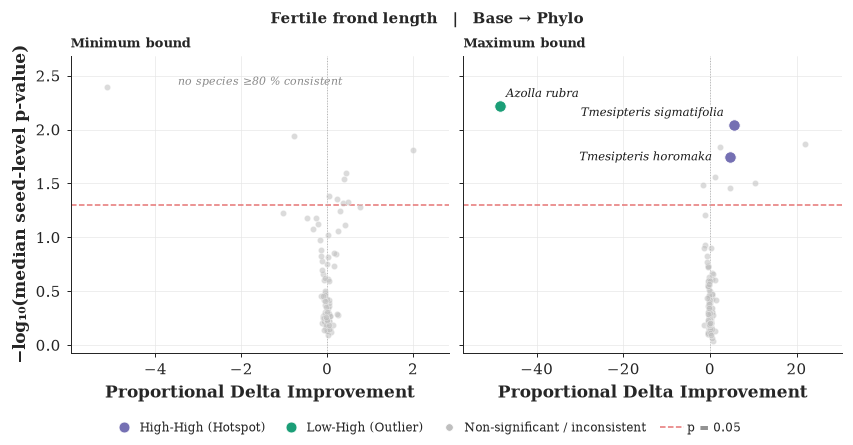

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Base_Phylo__Spore.pdf


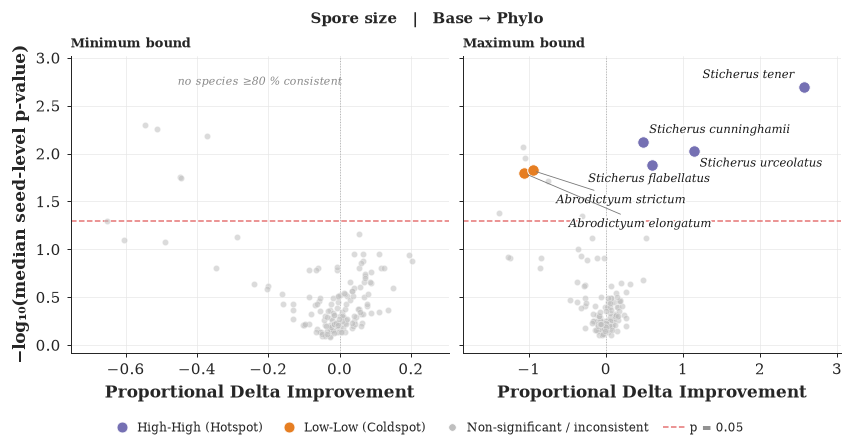

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Base_Phylo__SterileFrond.pdf


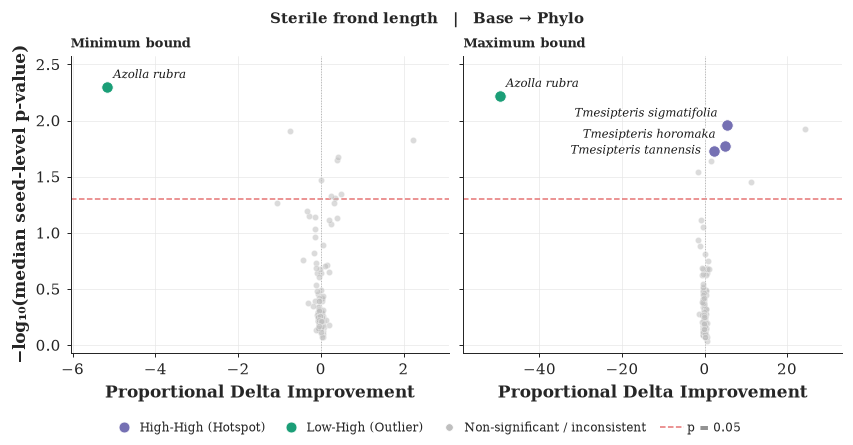

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo__FertileFrond.pdf


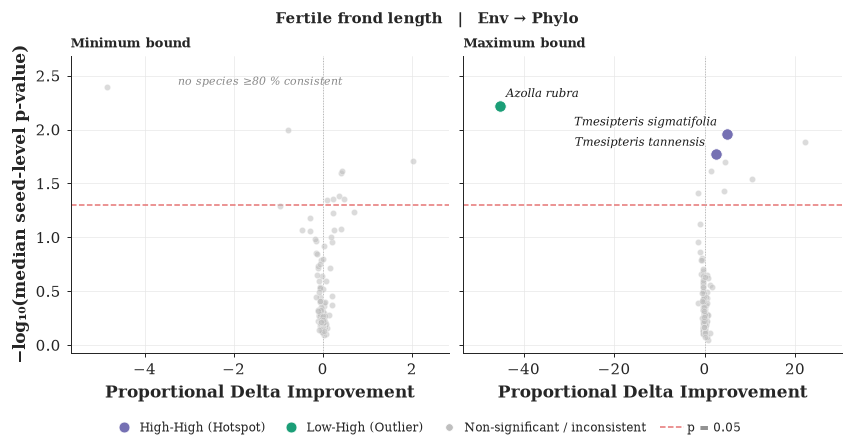

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo__Spore.pdf


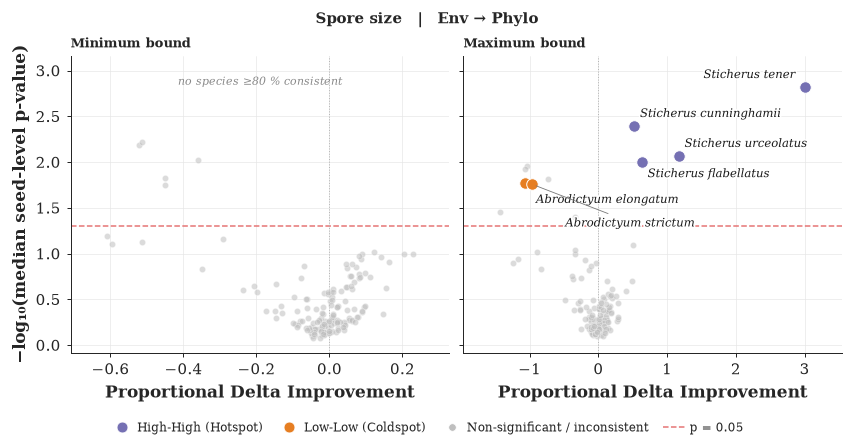

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo__SterileFrond.pdf


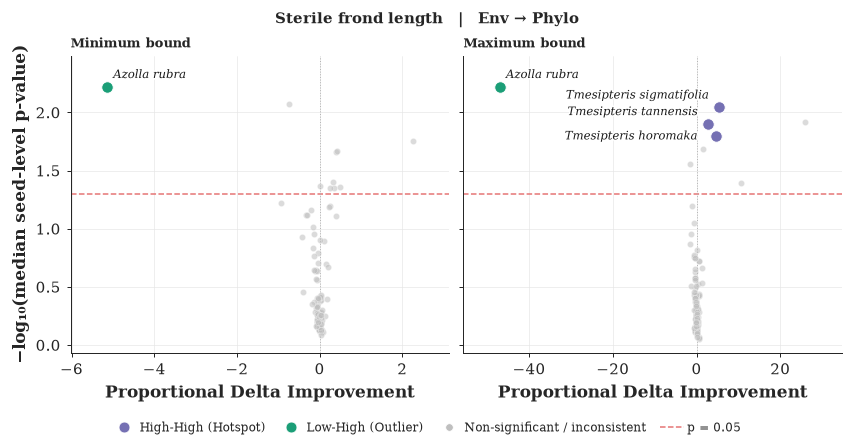

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo_Env__FertileFrond.pdf


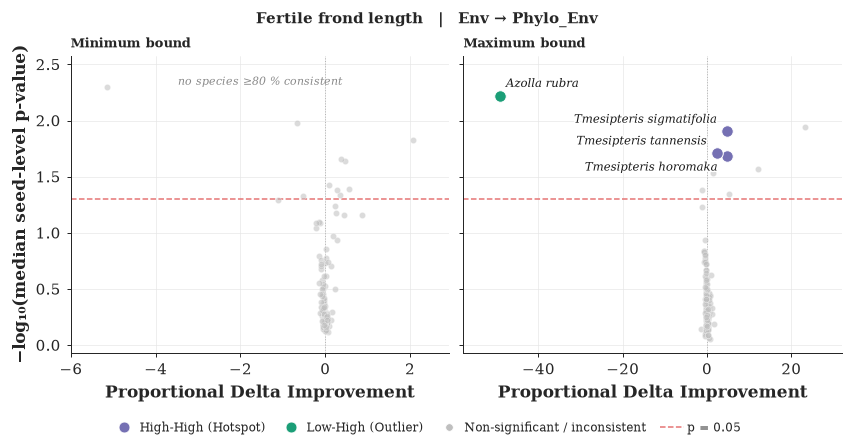

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo_Env__Spore.pdf


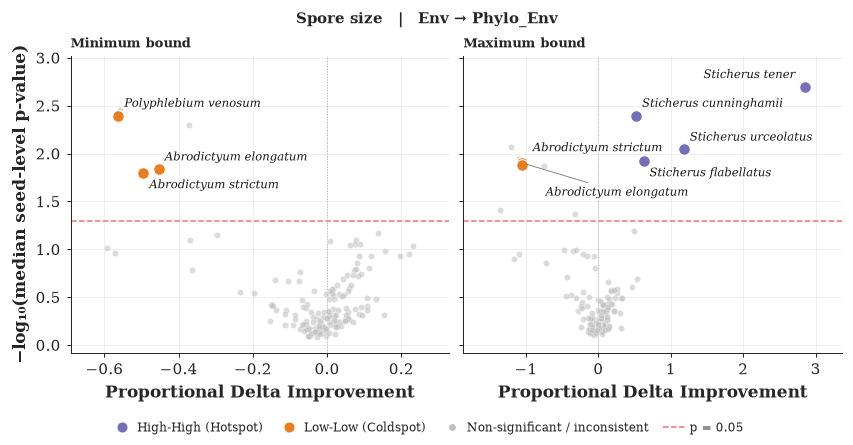

Saved figure to /home/smonaco/newzeland-plants/figures/lipa_80pct_Env_Phylo_Env__SterileFrond.pdf


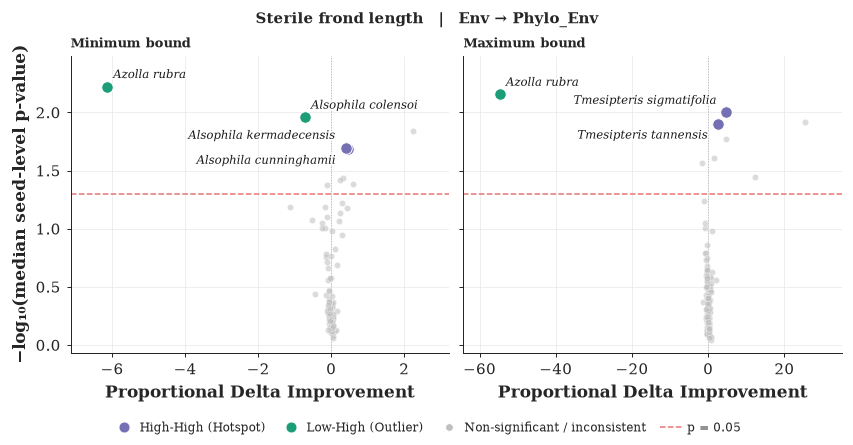

Created 9 paired LIPA figures.


In [14]:
lipa_pair_figures = plot_all_lipa_pairs(lipa_data)
print(f"Created {len(lipa_pair_figures)} paired LIPA figures.")
